# Stage 4: Model Training and Evaluation

This notebook trains three baseline models required by the assignment:
1. **Facial identity classification** using HOG features.
2. **Voiceprint identification** using MFCC, spectral roll-off, and RMS-energy features.
3. **Product-category recommendation** using customer transaction and social-profile features.

The dataset is very small, especially the face and voice data. The face and voice evaluations therefore use carefully separated original recordings/images and are demonstrations of the pipeline, not evidence of production-grade biometric accuracy.

**Leakage prevention:** augmented variants from one original image or recording must stay in the training partition with that original. The held-out test partition uses only genuine, unaugmented samples.

## 1. Imports and paths

Run from the project root or from the `notebooks/` folder. This notebook reads the CSV outputs from the preceding preprocessing stages.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    log_loss
)
from sklearn.base import clone
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
PROCESSED = DATA / "processed"
IMAGE_FEATURES_PATH = DATA / "images" / "processed" / "image_features.csv"
AUDIO_FEATURES_PATH = DATA / "audio" / "processed" / "audio_features.csv"
TABULAR_FEATURES_PATH = PROCESSED / "tabular_model_features.csv"
MERGED_PATH = PROCESSED / "customer_transactions_social_merged.csv"
MODEL_DIR = ROOT / "models"
REPORT_DIR = PROCESSED / "model_evaluation"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("Project root:", ROOT)
for path in [IMAGE_FEATURES_PATH, AUDIO_FEATURES_PATH, TABULAR_FEATURES_PATH, MERGED_PATH]:
    print(path.relative_to(ROOT), "exists:", path.exists())

Python: 3.14.6
Project root: c:\Users\a\Documents\formative_2_data_processing_personal
data\images\processed\image_features.csv exists: True
data\audio\processed\audio_features.csv exists: True
data\processed\tabular_model_features.csv exists: True
data\processed\customer_transactions_social_merged.csv exists: True


## 2. Shared evaluation helper

We report accuracy, weighted precision, weighted recall, and weighted F1. For classifiers that provide probabilities, we also report log loss. The confusion matrix and classification report help reveal class-level errors.

In [ ]:
evaluation_rows = []

def evaluate_classifier(task, model_name, model, X_train, y_train, X_test, y_test,
                        save_name, class_names=None):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test) if hasattr(model, "predict_proba") else None

    metrics = {
        "task": task,
        "model": model_name,
        "test_samples": len(y_test),
        "accuracy": accuracy_score(y_test, predictions),
        "precision_weighted": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "f1_weighted": f1_score(y_test, predictions, average="weighted", zero_division=0),
        "log_loss": log_loss(y_test, probabilities, labels=model.classes_) if probabilities is not None else np.nan
    }
    evaluation_rows.append(metrics)
    print(f"--- {task}: {model_name} ---")
    display(pd.Series(metrics).to_frame("value"))
    print(classification_report(y_test, predictions, zero_division=0))

    labels = model.classes_
    display_labels = class_names if class_names is not None else labels
    cm = confusion_matrix(y_test, predictions, labels=labels)
    display(ConfusionMatrixDisplay(cm, display_labels=display_labels).plot(
        xticks_rotation=45, cmap="Blues"
    ).figure)
    plt.show()
    joblib.dump(model, MODEL_DIR / save_name)
    return model, predictions

## 3. Facial identity model

The HOG table contains multiple augmented rows per original image. To avoid leakage, we:
- identify the original image paths for each participant;
- reserve one original image per participant for testing;
- train only on the remaining original images and their augmentations;
- test only on the held-out original image.

This is a very small test set, so the score is descriptive only.

In [3]:
if not IMAGE_FEATURES_PATH.exists():
    raise FileNotFoundError("Run the image preprocessing notebook first.")

image_df = pd.read_csv(IMAGE_FEATURES_PATH)
required_image_cols = {"source_path", "participant_id", "augmentation"}
missing = required_image_cols - set(image_df.columns)
if missing:
    raise ValueError(f"Image feature CSV is missing columns: {sorted(missing)}")

hog_cols = [c for c in image_df.columns if c.startswith("hog_")]
if not hog_cols:
    raise ValueError("No HOG feature columns were found.")

original_images = image_df[image_df["augmentation"].eq("original")].copy()
participant_sources = {
    participant: sorted(group["source_path"].unique())
    for participant, group in original_images.groupby("participant_id")
}
print("Original face images by participant:")
display(pd.Series({k: len(v) for k, v in participant_sources.items()}, name="original_images").to_frame())

if len(participant_sources) < 2 or any(len(paths) < 2 for paths in participant_sources.values()):
    raise ValueError(
        "Each participant needs at least two successfully processed original face images "
        "to create a leakage-safe train/test split. Collect more images or fix skipped images."
    )

face_test_sources = {participant: paths[-1] for participant, paths in participant_sources.items()}
face_test = original_images[original_images.apply(
    lambda row: face_test_sources.get(row["participant_id"]) == row["source_path"], axis=1
)].copy()
face_train = image_df[~image_df["source_path"].isin(face_test_sources.values())].copy()

X_face_train = face_train[hog_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
y_face_train = face_train["participant_id"].astype(str)
X_face_test = face_test[hog_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
y_face_test = face_test["participant_id"].astype(str)

print("Training rows (originals + training-only augmentations):", len(face_train))
print("Held-out original face images:", len(face_test))
print("Held-out participants:", sorted(y_face_test.unique()))

Original face images by participant:


,original_images
participant_01,3
participant_02,3
participant_03,2
participant_04,3


Training rows (originals + training-only augmentations): 35
Held-out original face images: 4
Held-out participants: ['participant_01', 'participant_02', 'participant_03', 'participant_04']


--- facial_identity: HOG + linear SVM ---


,value
task,facial_identity
model,HOG + linear SVM
test_samples,4
accuracy,1.0
precision_weighted,1.0
recall_weighted,1.0
f1_weighted,1.0
log_loss,0.420793


                precision    recall  f1-score   support

participant_01       1.00      1.00      1.00         1
participant_02       1.00      1.00      1.00         1
participant_03       1.00      1.00      1.00         1
participant_04       1.00      1.00      1.00         1

      accuracy                           1.00         4
     macro avg       1.00      1.00      1.00         4
  weighted avg       1.00      1.00      1.00         4



AttributeError: 'ConfusionMatrixDisplay' object has no attribute 'figure'

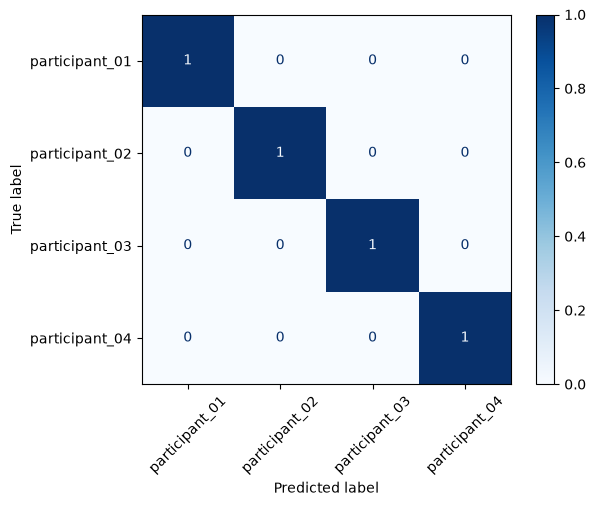

In [4]:
face_models = {
    "HOG + linear SVM": Pipeline([
        ("scale", StandardScaler()),
        ("classifier", SVC(kernel="linear", class_weight="balanced", probability=True, random_state=42))
    ]),
    "HOG + Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42,
        min_samples_leaf=1, n_jobs=-1
    )
}

for name, model in face_models.items():
    evaluate_classifier(
        "facial_identity", name, model,
        X_face_train, y_face_train, X_face_test, y_face_test,
        "face_" + ("svm" if "SVM" in name else "random_forest") + ".joblib"
    )

## 4. Voiceprint identification model

The voice dataset currently has two genuine recordings per participant: one for each phrase. We use the `yes_approve` recording and its augmentations for training, then test on the genuine `confirm_transaction` recording. This tests whether the baseline features can distinguish speakers across the two phrases.

The split is deliberately by original recording, not by augmented row. With only four held-out recordings, the evaluation is a proof of concept, not a reliable estimate of real-world voice verification performance.

In [ ]:
if not AUDIO_FEATURES_PATH.exists():
    raise FileNotFoundError("Run the audio preprocessing notebook first.")

audio_df = pd.read_csv(AUDIO_FEATURES_PATH)
required_audio_cols = {"source_path", "participant_id", "phrase", "augmentation"}
missing = required_audio_cols - set(audio_df.columns)
if missing:
    raise ValueError(f"Audio feature CSV is missing columns: {sorted(missing)}")

audio_meta = {"audio_path", "source_path", "participant_id", "phrase", "augmentation"}
audio_feature_cols = [
    c for c in audio_df.columns
    if c not in audio_meta and pd.api.types.is_numeric_dtype(audio_df[c])
]
if not audio_feature_cols:
    raise ValueError("No numeric audio feature columns were found.")

audio_originals = audio_df[audio_df["augmentation"].eq("original")].copy()
train_source_paths, test_source_paths = [], []
for participant, group in audio_originals.groupby("participant_id"):
    phrase_map = group.groupby("phrase")["source_path"].first().to_dict()
    if "yes_approve" not in phrase_map or "confirm_transaction" not in phrase_map:
        raise ValueError(
            f"{participant} needs one original recording for each required phrase."
        )
    train_source_paths.append(phrase_map["yes_approve"])
    test_source_paths.append(phrase_map["confirm_transaction"])

voice_train = audio_df[audio_df["source_path"].isin(train_source_paths)].copy()
voice_test = audio_originals[audio_originals["source_path"].isin(test_source_paths)].copy()

X_voice_train = voice_train[audio_feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
y_voice_train = voice_train["participant_id"].astype(str)
X_voice_test = voice_test[audio_feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
y_voice_test = voice_test["participant_id"].astype(str)

print("Training rows (one phrase + its augmentations per participant):", len(voice_train))
print("Held-out original recordings (other phrase):", len(voice_test))
display(voice_test[["participant_id", "phrase", "augmentation"]])

In [ ]:
voice_models = {
    "MFCC + RBF SVM": Pipeline([
        ("scale", StandardScaler()),
        ("classifier", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42))
    ]),
    "MFCC + Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42,
        min_samples_leaf=1, n_jobs=-1
    )
}

for name, model in voice_models.items():
    evaluate_classifier(
        "voiceprint_identification", name, model,
        X_voice_train, y_voice_train, X_voice_test, y_voice_test,
        "voice_" + ("svm" if "SVM" in name else "random_forest") + ".joblib"
    )

## 5. Product-category recommendation model

The target is `product_category`. Numeric features are median-imputed and scaled; categorical features are imputed and one-hot encoded. We exclude identifiers and post-purchase fields from the predictors.

Transactions from the same customer can be similar. To reduce customer leakage, we use `StratifiedGroupKFold` with customer ID as the group. We compare Logistic Regression and Random Forest on the same held-out fold and also report grouped cross-validation scores.

In [ ]:
if not TABULAR_FEATURES_PATH.exists() or not MERGED_PATH.exists():
    raise FileNotFoundError("Run the tabular preprocessing notebook first.")

tabular_Xy = pd.read_csv(TABULAR_FEATURES_PATH)
merged_for_groups = pd.read_csv(MERGED_PATH)

target = "product_category"
group_col = "customer_id_legacy"
if target not in tabular_Xy or group_col not in merged_for_groups:
    raise ValueError("The model feature table or merged table is missing its target/group column.")
if len(tabular_Xy) != len(merged_for_groups):
    raise ValueError("Feature rows do not align with merged transaction rows.")

y_product = tabular_Xy[target].astype(str)
groups = merged_for_groups[group_col].astype(str)

excluded_predictors = {
    target, "transaction_id", "customer_id_legacy", "customer_id_candidate",
    "customer_id_new", "purchase_amount", "customer_rating", "purchase_date"
}
X_product = tabular_Xy.drop(columns=[c for c in excluded_predictors if c in tabular_Xy.columns])
numeric_cols = X_product.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_product.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

product_models = {
    "Logistic Regression": Pipeline([
        ("preprocess", preprocessor),
        ("classifier", LogisticRegression(max_iter=3000, class_weight="balanced"))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=400, class_weight="balanced", random_state=42,
            min_samples_leaf=2, n_jobs=-1
        ))
    ])
}

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(X_product, y_product, groups))
X_product_train, X_product_test = X_product.iloc[train_idx], X_product.iloc[test_idx]
y_product_train, y_product_test = y_product.iloc[train_idx], y_product.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print("Rows:", len(X_product))
print("Train rows:", len(train_idx), "Test rows:", len(test_idx))
print("Train classes:", sorted(y_product_train.unique()))
print("Test classes:", sorted(y_product_test.unique()))
print("Customer groups overlap:", bool(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))
display(y_product.value_counts().rename("count").to_frame())

In [ ]:
for name, model in product_models.items():
    evaluate_classifier(
        "product_category", name, model,
        X_product_train, y_product_train, X_product_test, y_product_test,
        "product_" + ("logistic_regression" if "Logistic" in name else "random_forest") + ".joblib"
    )

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, model in product_models.items():
    scores = cross_validate(
        clone(model), X_product, y_product, groups=groups, cv=cv,
        scoring={"accuracy": "accuracy", "f1_weighted": "f1_weighted"},
        return_train_score=False, n_jobs=-1
    )
    cv_rows.append({
        "model": name,
        "cv_accuracy_mean": scores["test_accuracy"].mean(),
        "cv_accuracy_std": scores["test_accuracy"].std(),
        "cv_f1_weighted_mean": scores["test_f1_weighted"].mean(),
        "cv_f1_weighted_std": scores["test_f1_weighted"].std()
    })
cv_results = pd.DataFrame(cv_rows)
display(cv_results)

## 6. Compare model results

These results compare the baseline models on their respective held-out data. Face and voice test sets are tiny and should not be compared directly with the larger product-category test set.

In [ ]:
results_df = pd.DataFrame(evaluation_rows)
display(results_df.sort_values(["task", "f1_weighted"], ascending=[True, False]))
results_path = REPORT_DIR / "model_metrics.csv"
cv_path = REPORT_DIR / "product_grouped_cross_validation.csv"
results_df.to_csv(results_path, index=False)
cv_results.to_csv(cv_path, index=False)
print("Saved:", results_path)
print("Saved:", cv_path)

## 7. Interpretation, limitations, and next stage

- Face recognition is based on HOG descriptors and a very small number of original face images. It is a classroom baseline, not a secure identity system.
- Voiceprint identification is trained from one original phrase per participant and tested on the other phrase. Only four genuine recordings are held out, so results are highly uncertain.
- Product-category prediction uses transaction-level labels and customer-grouped validation to reduce leakage from repeated customers.
- Augmented rows are not independent people, images, or recordings. Never randomly split augmented variants across train and test.
- Report the actual test metrics and confusion matrices. Do not describe a tiny test result as proof of reliable biometric authentication.
- The next stage is the transaction simulation: a legitimate user should pass both identity checks before a product-category recommendation is shown; unauthorized face/voice attempts should be rejected.